# Knowledge Distillation — Vanilla KD Experiment

**Setup:** CIFAR-10 · ResNet-34 teacher · ResNet-18 student

This notebook is organized for Google Colab with a T4 GPU.

- CIFAR-10 is stored persistently in Google Drive.
- Training defaults to **50 epochs**.
- Start with the smoke-test cell using 5–10 epochs before committing to the full run.
- Best model weights are saved as `.pth`.
- Resume checkpoints are saved separately so a Colab disconnect does not waste completed epochs.

In [2]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import os
import sys
import time
import json
import random
import numpy as np
import torch

PROJECT_DIR = Path("/content/drive/MyDrive/kd_experiments")
DATA_DIR = PROJECT_DIR / "data"
WEIGHTS_DIR = PROJECT_DIR / "weights"
CHECKPOINTS_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"
LOGS_DIR = PROJECT_DIR / "logs"

for directory in [
    PROJECT_DIR, DATA_DIR, WEIGHTS_DIR, CHECKPOINTS_DIR, RESULTS_DIR, LOGS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project:", PROJECT_DIR)
print("Data:   ", DATA_DIR)
print("Weights:", WEIGHTS_DIR)
print("Device: ", device)

if torch.cuda.is_available():
    print("GPU:    ", torch.cuda.get_device_name(0))
    print("CUDA:   ", torch.version.cuda)

Mounted at /content/drive
Project: /content/drive/MyDrive/kd_experiments
Data:    /content/drive/MyDrive/kd_experiments/data
Weights: /content/drive/MyDrive/kd_experiments/weights
Device:  cuda
GPU:     Tesla T4
CUDA:    12.8


In [3]:
%cd /content

REPO_DIR = Path("/content/Knowledge-Distillation-Algorithms")

if not REPO_DIR.exists():
    !git clone https://github.com/shaswat-13/Knowledge-Distillation-Algorithms.git
else:
    print("Repository already exists — skipping clone.")

%cd /content/Knowledge-Distillation-Algorithms

!git checkout p-branch
!git pull origin p-branch

print("Current branch:")
!git branch --show-current

/content
Cloning into 'Knowledge-Distillation-Algorithms'...
remote: Enumerating objects: 64, done.
remote: Counting objects: 100% (64/64), done.
remote: Compressing objects: 100% (44/44), done.
remote: Total 64 (delta 20), reused 57 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (64/64), 330.24 KiB | 1.39 MiB/s, done.
Resolving deltas: 100% (20/20), done.
/content/Knowledge-Distillation-Algorithms
Branch 'p-branch' set up to track remote branch 'p-branch' from 'origin'.
Switched to a new branch 'p-branch'
From https://github.com/shaswat-13/Knowledge-Distillation-Algorithms
 * branch            p-branch   -> FETCH_HEAD
Already up to date.
Current branch:
p-branch


In [4]:
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader

import torchvision
import torchvision.transforms as transforms

from tqdm.auto import tqdm
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128


In [5]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

print("Seed:", SEED)
print("cuDNN benchmark:", torch.backends.cudnn.benchmark)

Seed: 42
cuDNN benchmark: True


In [6]:
CIFAR10_ROOT = str(DATA_DIR)

# CIFAR-10 normalization
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_dataset = torchvision.datasets.CIFAR10(
    root=CIFAR10_ROOT,
    train=True,
    download=True,
    transform=train_transform,
)

test_dataset = torchvision.datasets.CIFAR10(
    root=CIFAR10_ROOT,
    train=False,
    download=True,
    transform=test_transform,
)

print("Train samples:", len(train_dataset))
print("Test samples: ", len(test_dataset))
print("Dataset root: ", CIFAR10_ROOT)

100%|██████████| 170M/170M [37:11<00:00, 76.4kB/s]


Train samples: 50000
Test samples:  10000
Dataset root:  /content/drive/MyDrive/kd_experiments/data


In [7]:
BATCH_SIZE = 128
NUM_WORKERS = 2

pin_memory = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory,
    persistent_workers=(NUM_WORKERS > 0),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory,
    persistent_workers=(NUM_WORKERS > 0),
)

print("Batch size:", BATCH_SIZE)
print("Train batches:", len(train_loader))
print("Test batches:", len(test_loader))

Batch size: 128
Train batches: 391
Test batches: 79


## 7. Models

This notebook expects the project's ResNet implementation to be available from the cloned repository.

If your repository exposes the models under a different import path, this is the one cell we will adjust after the first import error.

In [9]:
import torch
import torch.nn as nn
from torchvision.models.resnet import ResNet, BasicBlock

def cifar_resnet18(num_classes=10):
    model = ResNet(
        block=BasicBlock,
        layers=[2, 2, 2, 2],
        num_classes=num_classes,
    )

    # CIFAR-10 uses 32x32 images, so replace the ImageNet-style stem.
    model.conv1 = nn.Conv2d(
        3, 64,
        kernel_size=3,
        stride=1,
        padding=1,
        bias=False,
    )
    model.maxpool = nn.Identity()

    return model


def cifar_resnet34(num_classes=10):
    model = ResNet(
        block=BasicBlock,
        layers=[3, 4, 6, 3],
        num_classes=num_classes,
    )

    model.conv1 = nn.Conv2d(
        3, 64,
        kernel_size=3,
        stride=1,
        padding=1,
        bias=False,
    )
    model.maxpool = nn.Identity()

    return model


# Create models
teacher = cifar_resnet34().to(device)
baseline_student = cifar_resnet18().to(device)
vanilla_student = cifar_resnet18().to(device)

print("Teacher parameters:",
      sum(p.numel() for p in teacher.parameters()))

print("Student parameters:",
      sum(p.numel() for p in baseline_student.parameters()))

Teacher parameters: 21282122
Student parameters: 11173962


In [10]:
NUM_EPOCHS = 50

# Smoke-test setting:
SMOKE_TEST_EPOCHS = 5

LEARNING_RATE = 0.1
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4

# Vanilla KD
TEMPERATURE = 4.0
ALPHA = 0.9

WEIGHT_FILES = {
    "teacher": "teacher_resnet34.pth",
    "baseline": "baseline_resnet18.pth",
    "vanilla": "vanilla_resnet18.pth",
}

CHECKPOINT_FILES = {
    "teacher": "teacher_resnet34_checkpoint.pth",
    "baseline": "baseline_resnet18_checkpoint.pth",
    "vanilla": "vanilla_resnet18_checkpoint.pth",
}

print(f"Final epochs: {NUM_EPOCHS}")
print(f"Smoke-test epochs: {SMOKE_TEST_EPOCHS}")
print(f"KD temperature: {TEMPERATURE}")
print(f"KD alpha: {ALPHA}")

Final epochs: 50
Smoke-test epochs: 5
KD temperature: 4.0
KD alpha: 0.9


In [11]:
def save_weights(model, filename):
    path = WEIGHTS_DIR / filename
    torch.save(model.state_dict(), path)
    print(f"Saved weights: {path}")
    return path


def save_training_checkpoint(
    model,
    optimizer,
    scheduler,
    epoch,
    best_accuracy,
    history,
    filename,
):
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict() if optimizer else None,
        "scheduler_state_dict": scheduler.state_dict() if scheduler else None,
        "best_accuracy": best_accuracy,
        "history": history,
    }

    path = CHECKPOINTS_DIR / filename
    torch.save(checkpoint, path)
    return path


def load_training_checkpoint(
    model,
    optimizer=None,
    scheduler=None,
    filename=None,
):
    path = CHECKPOINTS_DIR / filename

    checkpoint = torch.load(path, map_location=device)

    model.load_state_dict(checkpoint["model_state_dict"])

    if optimizer is not None and checkpoint["optimizer_state_dict"] is not None:
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    if scheduler is not None and checkpoint["scheduler_state_dict"] is not None:
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    print(f"Loaded checkpoint: {path}")
    print(f"Last completed epoch: {checkpoint['epoch']}")

    return checkpoint

In [12]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    criterion = nn.CrossEntropyLoss()

    for images, targets in loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            logits = model(images)
            loss = criterion(logits, targets)

        total_loss += loss.item() * targets.size(0)
        correct += (logits.argmax(dim=1) == targets).sum().item()
        total += targets.size(0)

    return total_loss / total, 100.0 * correct / total

In [13]:
def vanilla_kd_loss(
    student_logits,
    teacher_logits,
    targets,
    temperature=TEMPERATURE,
    alpha=ALPHA,
):
    # Hard-label loss
    hard_loss = F.cross_entropy(student_logits, targets)

    # Soft-label KD loss
    student_log_probs = F.log_softmax(student_logits / temperature, dim=1)
    teacher_probs = F.softmax(teacher_logits / temperature, dim=1)

    soft_loss = F.kl_div(
        student_log_probs,
        teacher_probs,
        reduction="batchmean",
    ) * (temperature ** 2)

    total_loss = alpha * soft_loss + (1.0 - alpha) * hard_loss

    return total_loss, hard_loss.detach(), soft_loss.detach()

In [14]:
def make_optimizer(model):
    return optim.SGD(
        model.parameters(),
        lr=LEARNING_RATE,
        momentum=MOMENTUM,
        weight_decay=WEIGHT_DECAY,
    )


def make_scheduler(optimizer, epochs):
    # Cosine schedule gives a smooth LR decay over the short experiment.
    return optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs,
    )


def train_standard_model(
    model,
    model_name,
    epochs=NUM_EPOCHS,
    resume=True,
):
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = make_optimizer(model)
    scheduler = make_scheduler(optimizer, epochs)

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=torch.cuda.is_available(),
    )

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "test_loss": [],
        "test_accuracy": [],
    }

    checkpoint_path = CHECKPOINTS_DIR / CHECKPOINT_FILES[model_name]
    start_epoch = 0
    best_accuracy = 0.0

    if resume and checkpoint_path.exists():
        checkpoint = load_training_checkpoint(
            model,
            optimizer,
            scheduler,
            CHECKPOINT_FILES[model_name],
        )
        start_epoch = checkpoint["epoch"]
        best_accuracy = checkpoint["best_accuracy"]
        history = checkpoint["history"]

        if start_epoch >= epochs:
            print(f"{model_name} already completed {start_epoch} epochs.")
            return model, history

    for epoch in range(start_epoch, epochs):
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        start_time = time.time()

        progress = tqdm(
            train_loader,
            desc=f"{model_name} | Epoch {epoch+1}/{epochs}",
            leave=False,
        )

        for images, targets in progress:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                "cuda",
                enabled=torch.cuda.is_available(),
            ):
                logits = model(images)
                loss = criterion(logits, targets)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * targets.size(0)
            correct += (logits.argmax(dim=1) == targets).sum().item()
            total += targets.size(0)

        scheduler.step()

        train_loss = running_loss / total
        train_accuracy = 100.0 * correct / total

        test_loss, test_accuracy = evaluate(model, test_loader)

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["test_loss"].append(test_loss)
        history["test_accuracy"].append(test_accuracy)

        elapsed = time.time() - start_time

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Test Loss: {test_loss:.4f} | "
            f"Test Acc: {test_accuracy:.2f}% | "
            f"Time: {elapsed/60:.2f} min"
        )

        # Save a resume checkpoint once per epoch.
        save_training_checkpoint(
            model,
            optimizer,
            scheduler,
            epoch + 1,
            best_accuracy,
            history,
            CHECKPOINT_FILES[model_name],
        )

        # Save best clean model weights.
        if test_accuracy > best_accuracy:
            best_accuracy = test_accuracy
            save_weights(model, WEIGHT_FILES[model_name])

    return model, history

In [15]:
def train_vanilla_kd(
    teacher,
    student,
    epochs=NUM_EPOCHS,
    resume=True,
):
    teacher = teacher.to(device)
    student = student.to(device)

    teacher.eval()

    optimizer = make_optimizer(student)
    scheduler = make_scheduler(optimizer, epochs)

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=torch.cuda.is_available(),
    )

    history = {
        "train_loss": [],
        "hard_loss": [],
        "soft_loss": [],
        "train_accuracy": [],
        "test_loss": [],
        "test_accuracy": [],
    }

    checkpoint_path = CHECKPOINTS_DIR / CHECKPOINT_FILES["vanilla"]
    start_epoch = 0
    best_accuracy = 0.0

    if resume and checkpoint_path.exists():
        checkpoint = load_training_checkpoint(
            student,
            optimizer,
            scheduler,
            CHECKPOINT_FILES["vanilla"],
        )
        start_epoch = checkpoint["epoch"]
        best_accuracy = checkpoint["best_accuracy"]
        history = checkpoint["history"]

        if start_epoch >= epochs:
            print(f"Vanilla KD already completed {start_epoch} epochs.")
            return student, history

    for epoch in range(start_epoch, epochs):
        student.train()

        running_loss = 0.0
        running_hard = 0.0
        running_soft = 0.0
        correct = 0
        total = 0

        start_time = time.time()

        progress = tqdm(
            train_loader,
            desc=f"Vanilla KD | Epoch {epoch+1}/{epochs}",
            leave=False,
        )

        for images, targets in progress:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            # Teacher does not need gradients.
            with torch.no_grad():
                with torch.amp.autocast(
                    "cuda",
                    enabled=torch.cuda.is_available(),
                ):
                    teacher_logits = teacher(images)

            with torch.amp.autocast(
                "cuda",
                enabled=torch.cuda.is_available(),
            ):
                student_logits = student(images)

                loss, hard_loss, soft_loss = vanilla_kd_loss(
                    student_logits,
                    teacher_logits,
                    targets,
                )

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            batch_size = targets.size(0)

            running_loss += loss.item() * batch_size
            running_hard += hard_loss.item() * batch_size
            running_soft += soft_loss.item() * batch_size

            correct += (
                student_logits.argmax(dim=1) == targets
            ).sum().item()

            total += batch_size

        scheduler.step()

        train_loss = running_loss / total
        hard_loss = running_hard / total
        soft_loss = running_soft / total
        train_accuracy = 100.0 * correct / total

        test_loss, test_accuracy = evaluate(student, test_loader)

        history["train_loss"].append(train_loss)
        history["hard_loss"].append(hard_loss)
        history["soft_loss"].append(soft_loss)
        history["train_accuracy"].append(train_accuracy)
        history["test_loss"].append(test_loss)
        history["test_accuracy"].append(test_accuracy)

        elapsed = time.time() - start_time

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"KD Loss: {train_loss:.4f} | "
            f"Hard: {hard_loss:.4f} | "
            f"Soft: {soft_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Test Acc: {test_accuracy:.2f}% | "
            f"Time: {elapsed/60:.2f} min"
        )

        save_training_checkpoint(
            student,
            optimizer,
            scheduler,
            epoch + 1,
            best_accuracy,
            history,
            CHECKPOINT_FILES["vanilla"],
        )

        if test_accuracy > best_accuracy:
            best_accuracy = test_accuracy
            save_weights(student, WEIGHT_FILES["vanilla"])

    return student, history

# 14. Smoke Test

Run this before the real 50-epoch experiment.

It trains only 5 epochs so we can verify:

- data loading
- model shapes
- GPU usage
- loss implementation
- checkpointing
- `.pth` saving

If everything looks good, change `epochs=SMOKE_TEST_EPOCHS` to `epochs=NUM_EPOCHS` in the actual training cells.

In [17]:
print("Teacher parameters:",
      sum(p.numel() for p in teacher.parameters()))

print("Student parameters:",
      sum(p.numel() for p in baseline_student.parameters()))

print("Models are ready.")

Teacher parameters: 21282122
Student parameters: 11173962
Models are ready.


In [18]:
baseline_student, baseline_history = train_standard_model(
baseline_student,
"baseline",
epochs=SMOKE_TEST_EPOCHS,
resume=False,
)

baseline | Epoch 1/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 1/5 | Train Loss: 2.0827 | Train Acc: 25.98% | Test Loss: 1.6454 | Test Acc: 38.75% | Time: 1.10 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/baseline_resnet18.pth


baseline | Epoch 2/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 2/5 | Train Loss: 1.4917 | Train Acc: 45.16% | Test Loss: 1.3376 | Test Acc: 51.47% | Time: 0.56 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/baseline_resnet18.pth


baseline | Epoch 3/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 3/5 | Train Loss: 1.1860 | Train Acc: 57.00% | Test Loss: 1.0367 | Test Acc: 63.29% | Time: 0.64 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/baseline_resnet18.pth


baseline | Epoch 4/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 4/5 | Train Loss: 0.9262 | Train Acc: 66.85% | Test Loss: 0.9193 | Test Acc: 68.18% | Time: 0.59 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/baseline_resnet18.pth


baseline | Epoch 5/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 5/5 | Train Loss: 0.7398 | Train Acc: 73.73% | Test Loss: 0.7491 | Test Acc: 73.86% | Time: 0.59 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/baseline_resnet18.pth


In [19]:

vanilla_student, vanilla_history = train_vanilla_kd(
    teacher,
    vanilla_student,
    epochs=SMOKE_TEST_EPOCHS,
    resume=False,
 )

print("Smoke-test cells are intentionally commented out.")
print("Uncomment one training block at a time after confirming the imports.")

Vanilla KD | Epoch 1/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 1/5 | KD Loss: 2.3262 | Hard: 11.5819 | Soft: 1.2978 | Train Acc: 10.04% | Test Acc: 10.00% | Time: 0.63 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/vanilla_resnet18.pth


Vanilla KD | Epoch 2/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 2/5 | KD Loss: 1.5143 | Hard: 11.3682 | Soft: 0.4194 | Train Acc: 9.54% | Test Acc: 9.92% | Time: 0.65 min


Vanilla KD | Epoch 3/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 3/5 | KD Loss: 1.4281 | Hard: 11.3894 | Soft: 0.3212 | Train Acc: 9.26% | Test Acc: 9.89% | Time: 0.65 min


Vanilla KD | Epoch 4/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 4/5 | KD Loss: 1.4036 | Hard: 11.3131 | Soft: 0.3025 | Train Acc: 9.26% | Test Acc: 10.01% | Time: 0.68 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/vanilla_resnet18.pth


Vanilla KD | Epoch 5/5:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 5/5 | KD Loss: 1.3889 | Hard: 11.2519 | Soft: 0.2930 | Train Acc: 9.34% | Test Acc: 10.03% | Time: 0.67 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/vanilla_resnet18.pth
Smoke-test cells are intentionally commented out.
Uncomment one training block at a time after confirming the imports.


In [20]:
# Delete smoke-test checkpoints and weights
import os

files_to_remove = [
    WEIGHTS_DIR / "teacher_resnet34.pth",
    WEIGHTS_DIR / "baseline_resnet18.pth",
    WEIGHTS_DIR / "vanilla_resnet18.pth",
    CHECKPOINTS_DIR / "teacher_resnet34_checkpoint.pth",
    CHECKPOINTS_DIR / "baseline_resnet18_checkpoint.pth",
    CHECKPOINTS_DIR / "vanilla_resnet18_checkpoint.pth",
]

for path in files_to_remove:
    if path.exists():
        path.unlink()
        print("Deleted:", path)

Deleted: /content/drive/MyDrive/kd_experiments/weights/baseline_resnet18.pth
Deleted: /content/drive/MyDrive/kd_experiments/weights/vanilla_resnet18.pth
Deleted: /content/drive/MyDrive/kd_experiments/checkpoints/baseline_resnet18_checkpoint.pth
Deleted: /content/drive/MyDrive/kd_experiments/checkpoints/vanilla_resnet18_checkpoint.pth


# 16. Final Training — 50 Epochs

Run these only after the smoke test works.

**Recommended order:**

1. Train teacher once.
2. Train baseline student once.
3. Train Vanilla KD.
4. Evaluate all saved models.

If a checkpoint already exists, `resume=True` allows training to continue rather than starting from scratch.

In [22]:
teacher = cifar_resnet34().to(device)

teacher, teacher_history = train_standard_model(
    teacher,
    "teacher",
    epochs=NUM_EPOCHS,
    resume=True,
)

teacher | Epoch 1/50:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 1/50 | Train Loss: 2.1698 | Train Acc: 24.39% | Test Loss: 1.9918 | Test Acc: 29.62% | Time: 0.69 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/teacher_resnet34.pth


teacher | Epoch 2/50:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 2/50 | Train Loss: 1.6443 | Train Acc: 38.85% | Test Loss: 1.6106 | Test Acc: 40.93% | Time: 0.69 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/teacher_resnet34.pth


teacher | Epoch 3/50:   0%|          | 0/391 [00:00<?, ?it/s]

...

Epoch 48/50 | Train Loss: 0.0055 | Train Acc: 99.89% | Test Loss: 0.2319 | Test Acc: 94.24% | Time: 0.78 min


teacher | Epoch 49/50:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 49/50 | Train Loss: 0.0050 | Train Acc: 99.89% | Test Loss: 0.2292 | Test Acc: 94.48% | Time: 0.77 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/teacher_resnet34.pth


teacher | Epoch 50/50:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 50/50 | Train Loss: 0.0052 | Train Acc: 99.89% | Test Loss: 0.2297 | Test Acc: 94.44% | Time: 0.79 min


In [24]:
#training baseline- 30 epochs
baseline_student = cifar_resnet18().to(device)

baseline_student, baseline_history = train_standard_model(
    baseline_student,
    "baseline",
    epochs=35,
    resume=True,
)

baseline | Epoch 1/35:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 1/35 | Train Loss: 1.9968 | Train Acc: 29.64% | Test Loss: 1.5493 | Test Acc: 42.44% | Time: 0.47 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/baseline_resnet18.pth


baseline | Epoch 2/35:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 2/35 | Train Loss: 1.4321 | Train Acc: 47.29% | Test Loss: 1.3041 | Test Acc: 53.08% | Time: 0.50 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/baseline_resnet18.pth


baseline | Epoch 3/35:   0%|          | 0/391 [00:00<?, ?it/s]

...

Epoch 33/35 | Train Loss: 0.0215 | Train Acc: 99.45% | Test Loss: 0.2169 | Test Acc: 93.71% | Time: 0.50 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/baseline_resnet18.pth


baseline | Epoch 34/35:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 34/35 | Train Loss: 0.0188 | Train Acc: 99.57% | Test Loss: 0.2192 | Test Acc: 93.77% | Time: 0.51 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/baseline_resnet18.pth


baseline | Epoch 35/35:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 35/35 | Train Loss: 0.0175 | Train Acc: 99.56% | Test Loss: 0.2173 | Test Acc: 93.76% | Time: 0.51 min


In [25]:
#training vanilla kd model
# Load the trained teacher weights before KD training.
teacher = cifar_resnet34().to(device)

teacher.load_state_dict(
    torch.load(
        WEIGHTS_DIR / WEIGHT_FILES["teacher"],
        map_location=device,
    )
)
teacher.eval()

# Create a fresh ResNet-18 student
vanilla_student = cifar_resnet18().to(device)

vanilla_student, vanilla_history = train_vanilla_kd(
    teacher,
    vanilla_student,
    epochs=35,
    resume=True,
)

Vanilla KD | Epoch 1/35:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 1/35 | KD Loss: 10.6371 | Hard: 2.3276 | Soft: 11.5603 | Train Acc: 33.09% | Test Acc: 44.73% | Time: 0.56 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/vanilla_resnet18.pth


Vanilla KD | Epoch 2/35:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 2/35 | KD Loss: 7.8659 | Hard: 1.8388 | Soft: 8.5355 | Train Acc: 49.92% | Test Acc: 52.99% | Time: 0.56 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/vanilla_resnet18.pth


Vanilla KD | Epoch 3/35:   0%|          | 0/391 [00:00<?, ?it/s]

...

Epoch 33/35 | KD Loss: 0.2237 | Hard: 0.0194 | Soft: 0.2464 | Train Acc: 99.38% | Test Acc: 94.10% | Time: 0.58 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/vanilla_resnet18.pth


Vanilla KD | Epoch 34/35:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 34/35 | KD Loss: 0.2167 | Hard: 0.0169 | Soft: 0.2389 | Train Acc: 99.51% | Test Acc: 94.18% | Time: 0.62 min
Saved weights: /content/drive/MyDrive/kd_experiments/weights/vanilla_resnet18.pth


Vanilla KD | Epoch 35/35:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 35/35 | KD Loss: 0.2163 | Hard: 0.0175 | Soft: 0.2384 | Train Acc: 99.46% | Test Acc: 94.04% | Time: 0.59 min


In [27]:
# FINAL MODEL EVALUATION
def load_weights(model, filename):
    path = WEIGHTS_DIR / filename
    model.load_state_dict(torch.load(path, map_location=device))
    model.to(device)
    model.eval()
    return model

teacher_eval = load_weights(
    cifar_resnet34(),
    WEIGHT_FILES["teacher"],
)

baseline_eval = load_weights(
    cifar_resnet18(),
    WEIGHT_FILES["baseline"],
)

vanilla_eval = load_weights(
    cifar_resnet18(),
    WEIGHT_FILES["vanilla"],
)

models = {
    "Teacher ResNet-34": teacher_eval,
    "Baseline ResNet-18": baseline_eval,
    "Vanilla KD ResNet-18": vanilla_eval,
}

results = {}

for name, model in models.items():
    loss, accuracy = evaluate(model, test_loader)
    results[name] = {
        "test_loss": loss,
        "test_accuracy": accuracy,
    }

    print(
        f"{name}: "
        f"Loss={loss:.4f}, "
        f"Accuracy={accuracy:.2f}%"
    )

Teacher ResNet-34: Loss=0.2292, Accuracy=94.48%
Baseline ResNet-18: Loss=0.2192, Accuracy=93.77%
Vanilla KD ResNet-18: Loss=0.2614, Accuracy=94.18%


In [28]:
results_path = RESULTS_DIR / "vanilla_kd_results.json"

with open(results_path, "w") as f:
    json.dump(results, f, indent=2)

print("Results saved to:", results_path)

print("\nWeights currently in Drive:")
for path in sorted(WEIGHTS_DIR.glob("*.pth")):
    print(" -", path.name)

Results saved to: /content/drive/MyDrive/kd_experiments/results/vanilla_kd_results.json

Weights currently in Drive:
 - baseline_resnet18.pth
 - teacher_resnet34.pth
 - vanilla_resnet18.pth


In [30]:
def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history["train_loss"], label="Train Loss")
    plt.plot(epochs, history["test_loss"], label="Test Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history["train_accuracy"], label="Train Accuracy")
    plt.plot(epochs, history["test_accuracy"], label="Test Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


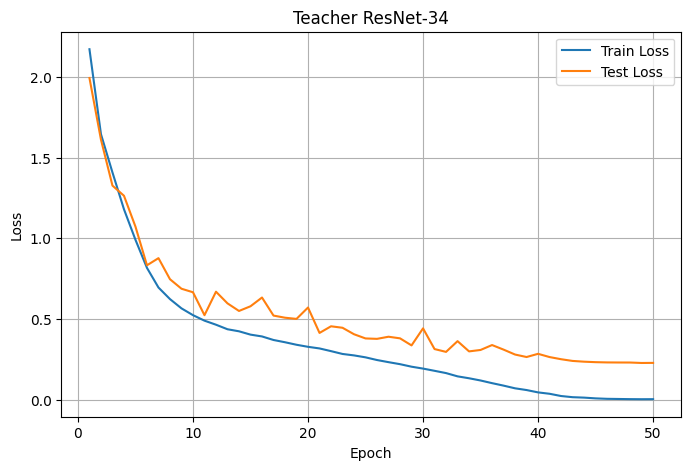

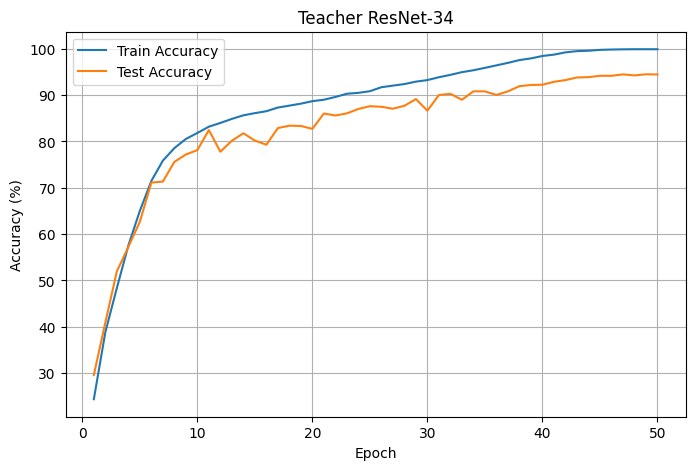

In [33]:
plot_history(teacher_history, "Teacher ResNet-34")

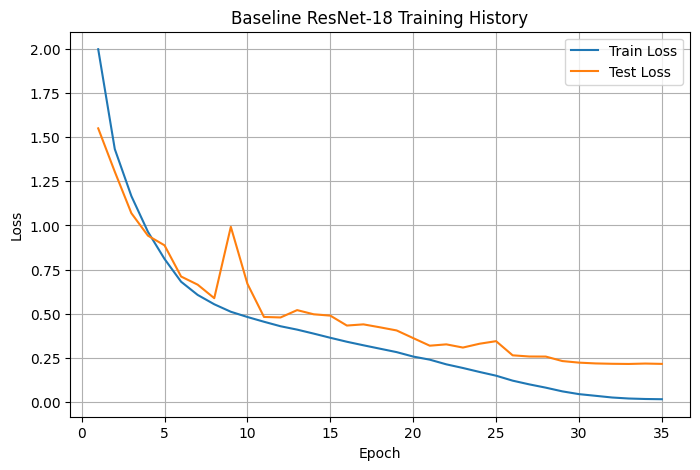

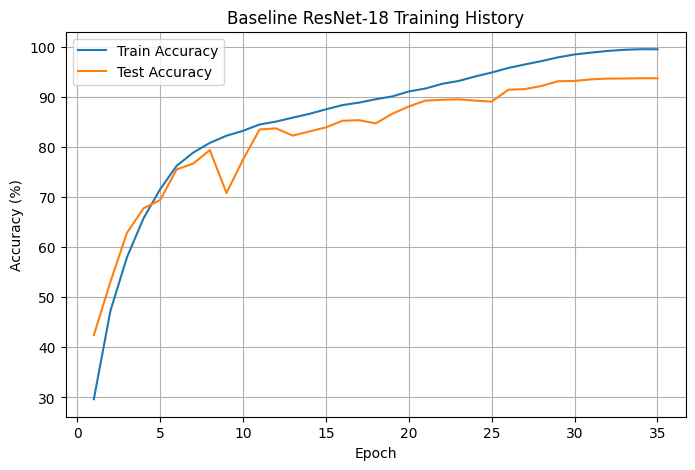

In [31]:
plot_history(baseline_history, "Baseline ResNet-18 Training History")

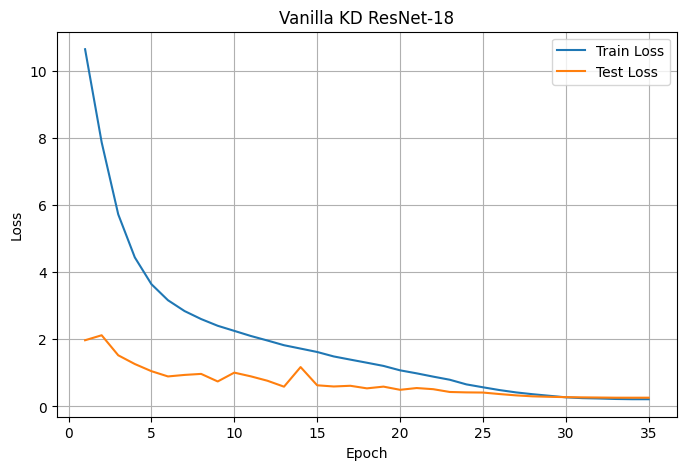

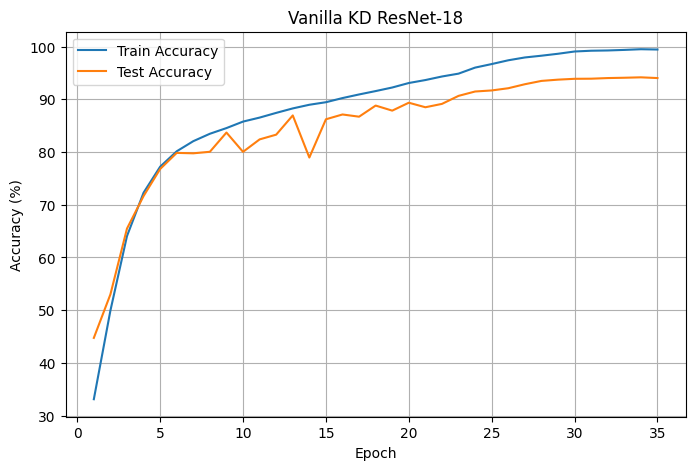

In [34]:
plot_history(vanilla_history, "Vanilla KD ResNet-18")